<table>
<tr><td><img style="height: 150px;" src="images/geo_hydro1.jpg"></td>
<td bgcolor="#FFFFFF">
    <p style="font-size: xx-large; font-weight: 900; line-height: 100%">pyRANDOM</p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);"><b style=color:red;>RANDOM</b> <b style=color:red;>NUMBERS</b></p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);">Georg Kaufmann</p>
    </td>
<td><img style="height: 150px;" src="images/pyRANDOM.png"></td>
</tr>
</table>

----
# `pyRANDOM`

pyRANDOM, a collection of jupyter notebooks playing with **random numbers** ...

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate
import ipywidgets as widgets
from ipywidgets import interactive

----
# Gaussian distribution
In this notebook, we have a closer look at the **normal** ranndom-number distribution,
which follows a **Gaussian** function.

We re-run the normal sequence from the previous notebook with more numbers:

In [2]:
rng = np.random.default_rng(seed=42)
print(rng)

Generator(PCG64)


In [3]:
def runPCGnormal(mu=0,sigma=1,n=100):
    """
    run and plot random data created with permutation congruential generator
    """
    r1 = rng.normal(mu,sigma,n)
    mu    = r1.mean()
    sigma = r1.std()
    print('mu: ',mu,' sigma: ',sigma)

    fig,axs = plt.subplots(1,2,figsize=(12,4))
    axs[0].set_title('Normal distribution')
    axs[0].set_xlabel('No of samples')
    axs[0].set_ylabel('Random value')
    axs[0].plot(r1,lw=1,alpha=0.3,color=(0.2,0.2,0.2))
    axs[0].plot(r1,lw=0,marker='o',label='uniform')


    axs[1].set_xlabel('Random value')
    axs[1].set_ylabel('#')
    axs[1].hist(r1,bins=10,rwidth=0.9,label='#')
    return r1,mu,sigma

mu:  1.9855542245020268  sigma:  0.494361177698254


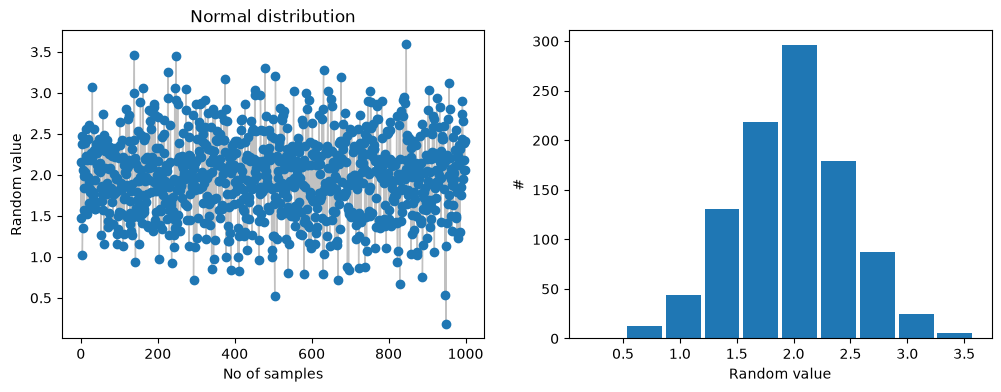

In [4]:
r1,mu,sigma = runPCGnormal(mu=2,sigma=0.5,n=1000)

As the histogram resembles an exponential function, use compare it to the **Gaussian function**:
$$
f(x) = \frac{1}{\sqrt{2\pi} \sigma} e^{-\frac{(x-\mu)^2}{2 \sigma^2}}
$$
The Gaussian function is normalised in such a way, that the integral under the curve is `1` (We test it later ...). 

In [5]:
def gaussianFunction(x,mu=0,sigma=1):
    # Gauss probability function
    y = 1/(sigma * np.sqrt(2*np.pi)) * np.exp( -((x-mu)/sigma)**2 / 2 )
    return y

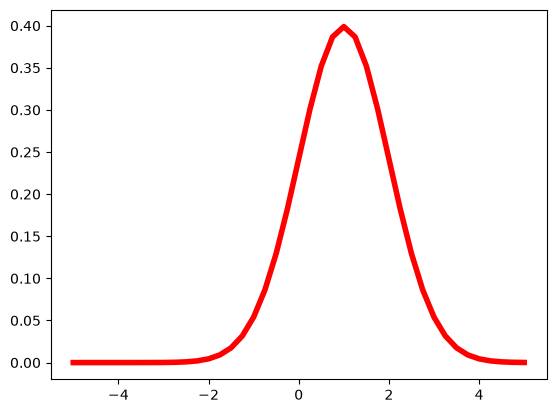

In [6]:
x = np.linspace(-5,5,41)
plt.plot(x,gaussianFunction(x,mu=1,sigma=1),lw=4,color='red',label='Gauss')

We plot the Gaussian function on top of the histogram. 
Note that we use the keyword `density=True` in the `hist` function. This keyword triggers a re-scaling of the
area under the enclosed histogram to `1` (see help page of `hist()`).



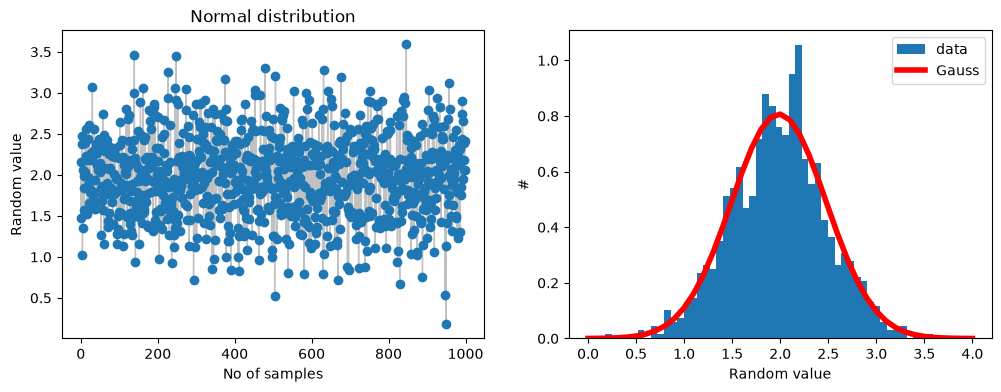

In [7]:
fig,axs = plt.subplots(1,2,figsize=(12,4))
axs[0].set_title('Normal distribution')
axs[0].set_xlabel('No of samples')
axs[0].set_ylabel('Random value')
axs[0].plot(r1,lw=1,alpha=0.3,color=(0.2,0.2,0.2))
axs[0].plot(r1,lw=0,marker='o',label='uniform')


axs[1].set_xlabel('Random value')
axs[1].set_ylabel('#')
axs[1].hist(r1,bins=50,rwidth=1,label='data',density=True)
x = np.linspace(0,4,41)
axs[1].plot(x,gaussianFunction(x,mu,sigma),lw=4,color='red',label='Gauss')
axs[1].legend()

In the plot above, we find our standard deviation $\sigma$ as half-width. 

- Around 68.27 % of all points are within the $1 \sigma$ uncertainty.
- Around 95.45 % of all points are within the $2 \sigma$ uncertainty.
- Around 99.73 % of all points are within the $3 \sigma$ uncertainty.

We could figure this numbers out by integrating the above curve ...

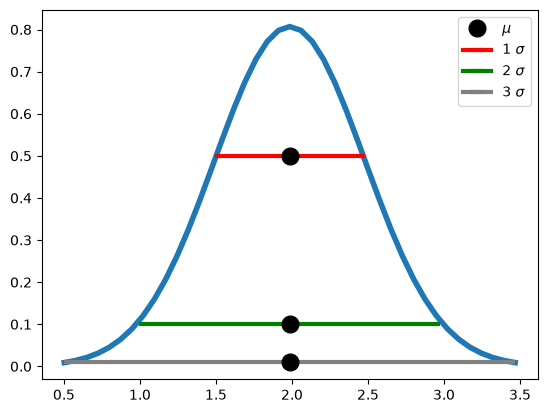

In [9]:
# plot function first for visualisation
x = np.linspace(-3*sigma+mu,3*sigma+mu,41)
y = gaussianFunction(x,mu,sigma)
plt.plot(x,y,lw=4)

plt.errorbar(mu, 0.5, xerr=sigma,lw=3,color='red',label='1 $\\sigma$')
plt.plot(mu,0.5,linestyle='none',marker='o',markersize=12,color='black',label='$\\mu$')

plt.errorbar(mu, 0.1, xerr=2*sigma,lw=3,color='green',label='2 $\\sigma$')
plt.plot(mu,0.1,linestyle='none',marker='o',markersize=12,color='black')

plt.errorbar(mu, 0.01, xerr=3*sigma,lw=3,color='gray',label='3 $\\sigma$')
plt.plot(mu,0.01,linestyle='none',marker='o',markersize=12,color='black')
plt.legend()

## Gauss distribution: the $\sigma$ estimates ...

We have said, that the probabilities for a sample to be within the $\pm 1\sigma$, $\pm 2\sigma$,
or $\pm 3\sigma$ range is:

- Around 68.27 % of all points are within the $1 \sigma$ uncertainty.
- Around 95.45 % of all points are within the $2 \sigma$ uncertainty.
- Around 99.73 % of all points are within the $3 \sigma$ uncertainty.

Let's calculate these values. We just need to integrate the above function from
$x \in [-1 \sigma,+1 \sigma]$,
$x \in [-2 \sigma,+2 \sigma]$,
$x \in [-3 \sigma,+3 \sigma]$.
We use the `quad` quadrature rule from the `scipy.integrate` package.

In [10]:
# perform numerical integration three times
onesigma   = scipy.integrate.quad(gaussianFunction,-1*sigma+mu,1*sigma+mu,args=(mu,sigma,))
twosigma   = scipy.integrate.quad(gaussianFunction,-2*sigma+mu,2*sigma+mu,args=(mu,sigma,))
threesigma = scipy.integrate.quad(gaussianFunction,-3*sigma+mu,3*sigma+mu,args=(mu,sigma,))
print ("%s %4.2f %s" % ('1-sigma: ',100*onesigma[0],'%'))
print ("%s %4.2f %s" % ('2-sigma: ',100*twosigma[0],'%'))
print ("%s %4.2f %s" % ('3-sigma: ',100*threesigma[0],'%'))

1-sigma:  68.27 %
2-sigma:  95.45 %
3-sigma:  99.73 %


Thus the statement above was correct. Also, the area under the Gaussian curve is one, as the last integration indicates.

----